# Molecular MD statistics from a simulation directory

Point `SIMULATION_DIR` at your LAMMPS run directory and run the cells. This notebook reads the input and text dump directly; no reports from the earlier notebooks are required.

All displacement and correlation statistics use **all molecules of each species**. There is no arbitrary subset of atoms. Molecules are identified from the first frame's bond graph and retain those identities throughout. Formula labels distinguish species, but do not distinguish isomers. This is a nonreactive, fixed-topology analysis.

The analysis uses metal units and a constant timestep. Set UNITS and TIMESTEP_PS explicitly below. These values take precedence and bypass input parsing and header inference. An input file is not required. Set either value to None only when you want file metadata to supply it; restart binary files are not parsed. Supported dump suffixes are `.lammpstrj` and `.dump`; explicit filenames can use other suffixes. Unique input/dump files are discovered recursively. If several match, choose the filenames explicitly instead of silently analyzing the wrong run.

After updating the package, restart the kernel and run all cells so imported function definitions match the notebook. Explicit UNITS and TIMESTEP_PS bypass input-script parsing.

Set `CACHE_DIR` to an existing `postprocess/cache` to skip trajectory parsing. The fixed-reference MSD and individual squared-displacement plots run directly after the MSD-versus-lag plots.


Window selection uses **zero-based source dump frames**: `STARTFRAME` is inclusive and `ENDFRAME` exclusive. The defaults (`0`, `None`) use the entire loaded trajectory. With stride 2, `[3, 9)` selects source frames 4, 6, 8. These indices are not LAMMPS timesteps or rows after striding. Lag and diffusion-fit settings remain in ps.

Pair analysis now caches initial topology and reuses whole-molecule coordinates. Start with `PAIR_WORKERS=1`; try `2` or `4` only if benchmarking shows a benefit. `PAIR_BACKEND="reference"` with one worker retains the older per-frame graph reconstruction. Cached analysis assumes fixed connectivity and preserves molecular ID sets; atom-list order is fixed from the first frame. Frames remain chronological for unwrapping and pair lifetimes. A notebook can call process workers directly; standalone scripts must use an `if __name__ == "__main__":` guard.

In [ ]:
from pathlib import Path
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from MartiniFuncs.trajectory.analysis import analyze_run, molecular_window_statistics
from MartiniFuncs.pairs import lifetimes
from MartiniFuncs.statistics import md
from MartiniFuncs.chemistry.cpd_n4t import CpdN4tCollection, CpdN4tCriteria
from MartiniFuncs.pairs.candidates import select_pairs

# Usually this is the only path to change.
# SIMULATION_DIR = Path(r"C:/Users/nicho/Documents/Martini collab/uma_data/smaller_system/continued_run")
SIMULATION_DIR = Path(r"C:/Users/nicho/Documents/Martini collab/uma_data/NVT_noshear")
INPUT_FILE = None   # optional with explicit UNITS/TIMESTEP_PS; e.g. "infile.in"; required only if discovery is ambiguous
DUMP_FILE = None    # e.g. "output/equilibrate.lammpstrj"
DATA_FILE = None    # optional species/mass fallback; use the matching initial data file

TYPE_SYMBOLS = None  # optional {1: "C", 2: "H", ...} for missing dump elements
UNITS = "metal"  # explicit LAMMPS source units
TIMESTEP_PS = 0.0005  # ps per MD step; 0.5 fs

FRAME_STRIDE = 1
MAX_FRAMES = None   # set e.g. 200 for a quick preview; caps SOURCE frames read
BOND_SCALE = 1.3
TEMPERATURE_DOF = "3N-3"  # unconstrained atoms, 3 COM DOF removed; change for constraints
# Set TEMPERATURE_DOF=None to omit temperature rather than assume this convention.

COMPUTE_PAIRS = True  # optional CPD/dienophile pair analysis
# Stage 1, collection: every pair with CPD COM to C=C COM below REACTIVE_RADIUS (Angstrom) is measured.
REACTIVE_RADIUS = 3.25
# Stage 2, selection of collected pairs for the lifetimes, e.g. CpdN4tCriteria(max_forming_distance=4.0,
# max_ring_dihedral_deviation=30); None uses every collected pair.
PAIR_CRITERIA = None
PAIR_BACKEND = "cached"  # reuse initial molecular topology; "reference" rebuilds each frame
PAIR_WORKERS = 1  # try 2 or 4 for larger workloads; processes can be slower for small runs
PAIR_BATCH_SIZE = 32  # retained frames per task; at most 2*workers tasks in flight

STARTFRAME = 0     # inclusive, zero-based source dump frame
ENDFRAME = None    # exclusive source frame; None uses the end
MAX_LAG_PS = 100.0
DIFFUSION_FIT_PS = None  # e.g. (50, 100), only after inspecting molecular MSD
SAVE_PLOTS = False
PLOT_DIR = SIMULATION_DIR / "md_statistics_plots"

# Optional LAMMPS thermo output; no dump processing is required for these plots.
LOAD_THERMO = True
THERMO_FILE = None  # relative/absolute .out or log path; None discovers a unique file
THERMO_BLOCK = None  # zero-based table number; auto-select only a single table

CACHE_DIR = None  # Optional Path("/path/to/postprocess/cache"); skips dump analysis when set.


## LAMMPS temperature and pressure from `.out` / log files

Run this section independently of the trajectory analysis below. It reads ordinary
LAMMPS `Step ...` thermo tables; it does not read atom coordinates or run UMA.
`LOAD_THERMO` enables loading. `THERMO_FILE=None` discovers a unique `.out`, `.log`
or `log*` containing a thermo table in the run directory; specify a relative or
absolute filename if multiple files match. Missing output is reported and skipped.
`THERMO_BLOCK` is a **zero-based thermo table number**, not a frame or timestep.
If several tables exist, inspect their ranges and choose one explicitly.

`thermo` retains all tables and original/custom columns; `thermo_selected` contains
the chosen table. Standard aliases include `temperature_K`, `pressure_bar`, and
energy columns when printed. The plots show raw samples, with no smoothing or
equilibrium claim. Their x-axis uses printed `Time` in ps if available, otherwise
the LAMMPS timestep. Thermo sampling need not match dump sampling.

For `metal` units, $T$ is in K and $P$ in bar
($P_{\mathrm{GPa}}=10^{-4}P_{\mathrm{bar}}$). These are **LAMMPS's printed values**;
the reader does not recompute $T=2K_{\mathrm{thermal}}/(f k_B)$ or choose its
degrees of freedom $f$. Under shear, verify which temperature compute the input
uses: parsing does not remove streaming velocity. Printed energies retain the
run's `thermo_modify norm` convention (total or per atom).

This table is kept separate from dump-derived `frames`, so it cannot silently
overwrite a differently defined temperature. For an exact-timestep join, use
`MartiniFuncs.io.thermo.attach_thermo` after explicitly resolving overlapping column
names. Unmatched dump samples become NaN, not interpolated values.


In [6]:
THERMO_DIRECTORY = SIMULATION_DIR
from pathlib import Path
import importlib
import matplotlib.pyplot as plt
from IPython.display import display
import MartiniFuncs.io.thermo as thermo_io

# Refresh this stateless reader when rerunning in a previously open kernel.
thermo_io = importlib.reload(thermo_io)
thermo = thermo_selected = thermo_source = None
if LOAD_THERMO:
    thermo_source = thermo_io.discover_thermo_file(THERMO_DIRECTORY, thermo_file=THERMO_FILE)
    if thermo_source is None:
        print("No LAMMPS thermo table found; skipping thermo plots.")
    else:
        thermo = thermo_io.read_lammps_thermo(thermo_source, units=UNITS)
        print("Thermo source:", thermo_source)
        print("Available columns:", list(thermo.columns))
        blocks = thermo.groupby("thermo_block")["timestep"].agg(["min", "max", "count"])
        display(blocks.rename(columns={"min": "first_step", "max": "last_step", "count": "samples"}))
        if THERMO_BLOCK is None and len(blocks) > 1:
            print("Multiple tables: set THERMO_BLOCK to a table number above, then rerun this section.")
        else:
            selected_block = blocks.index[0] if THERMO_BLOCK is None else THERMO_BLOCK
            if selected_block not in blocks.index:
                raise ValueError(f"THERMO_BLOCK={selected_block} is absent; available: {list(blocks.index)}")
            thermo_selected = thermo.loc[thermo.thermo_block == selected_block].copy()
            display(thermo_selected.head())
else:
    print("Thermo loading disabled (LOAD_THERMO=False).")


Thermo source: C:\Users\nicho\Documents\Martini collab\uma_data\smaller_system\continued_run\uma_4gpu_570282.out
Available columns: ['Step', 'Time', 'Temp', 'PotEng', 'KinEng', 'TotEng', 'Press', 'Pxx', 'Pyy', 'Pzz', 'Pxy', 'Volume', 'Density', 'Lx', 'Ly', 'Lz', 'Xy', 'thermo_block', 'source_line', 'timestep', 'thermo_time_ps', 'temperature_K', 'pressure_bar', 'potential_energy_eV', 'kinetic_energy_eV', 'total_energy_eV', 'thermo_volume_angstrom3', 'thermo_density_g_cm3', 'pxx_bar', 'pyy_bar', 'pzz_bar', 'pxy_bar']


,first_step,last_step,samples
thermo_block,,,
0,2000000,4000000,1001


,Step,Time,Temp,PotEng,KinEng,TotEng,Press,Pxx,Pyy,Pzz,...,pressure_bar,potential_energy_eV,kinetic_energy_eV,total_energy_eV,thermo_volume_angstrom3,thermo_density_g_cm3,pxx_bar,pyy_bar,pzz_bar,pxy_bar
0,2000000,1000.0,407.54859,-896788.30,71.591834,-896716.71,32282.217,35308.047,33739.842,27798.762,...,32282.217,-896788.30,71.591834,-896716.71,11721.036,1.435423,35308.047,33739.842,27798.762,1391.208800
1,2002000,1001.0,399.28256,-896786.34,70.139785,-896716.20,22404.293,24427.473,26032.989,16752.416,...,22404.293,-896786.34,70.139785,-896716.20,11741.282,1.432948,24427.473,26032.989,16752.416,-142.951280
2,2004000,1002.0,408.38880,-896786.95,71.739429,-896715.21,23974.882,27210.861,20254.006,24459.781,...,23974.882,-896786.95,71.739429,-896715.21,11720.020,1.435548,27210.861,20254.006,24459.781,-2404.966700
3,2006000,1003.0,400.52407,-896785.50,70.357874,-896715.15,27461.033,29815.842,29570.136,22997.121,...,27461.033,-896785.50,70.357874,-896715.15,11780.236,1.428210,29815.842,29570.136,22997.121,-1086.629100
4,2008000,1004.0,416.55800,-896790.11,73.174468,-896716.93,26113.250,28536.918,24676.325,25126.509,...,26113.250,-896790.11,73.174468,-896716.93,11806.224,1.425066,28536.918,24676.325,25126.509,-75.978506


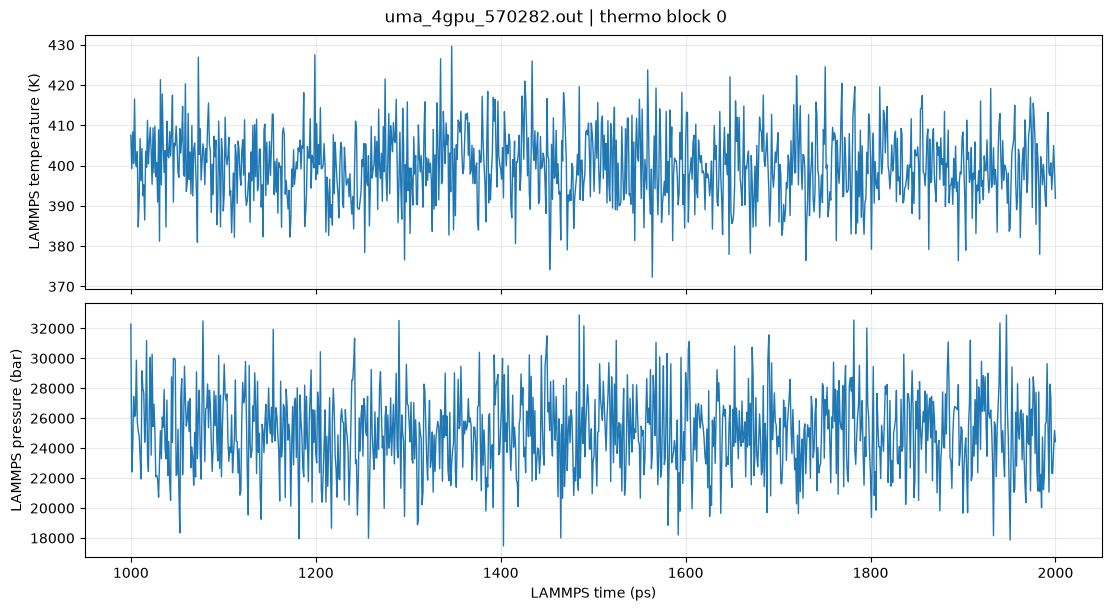

In [7]:
if thermo_selected is not None:
    thermo_observables = [(column, label) for column, label in
                         [("temperature_K", "LAMMPS temperature (K)"),
                          ("pressure_bar", "LAMMPS pressure (bar)")]
                         if column in thermo_selected and thermo_selected[column].notna().any()]
    if not thermo_observables:
        print("Selected table has no Temp/Press data; inspect its available columns above.")
    else:
        thermo_x = ("thermo_time_ps" if "thermo_time_ps" in thermo_selected
                    and thermo_selected["thermo_time_ps"].notna().all() else "timestep")
        thermo_fig, thermo_axes = plt.subplots(len(thermo_observables), 1, squeeze=False,
                                               figsize=(11, 3*len(thermo_observables)),
                                               sharex=True, layout="constrained")
        for ax, (column, label) in zip(thermo_axes[:, 0], thermo_observables):
            ax.plot(thermo_selected[thermo_x], thermo_selected[column], linewidth=1)
            ax.set_ylabel(label)
            ax.grid(alpha=.25)
        thermo_axes[-1, 0].set_xlabel("LAMMPS time (ps)" if thermo_x == "thermo_time_ps" else "LAMMPS timestep")
        thermo_fig.suptitle(f"{thermo_source.name} | thermo block {selected_block}")
        plt.show()


`MAX_FRAMES` limits the available source frames for a preview; it does not select equilibrated data. `STARTFRAME`/`ENDFRAME` select a range within those available frames. Defaults use all available frames; selected frame bounds and physical times are printed.

### Mathematics: frames, time, units and molecular identity
Let $f$ be the zero-based source frame, $s_f$ its LAMMPS timestep, and $h=$ `TIMESTEP_PS` (ps per MD step). The displayed time is
$$t_f=s_fh.$$
`FRAME_INDEX` / `FRAME_INDICES` select $f$, not $s_f$. Where present, `FRAME_STRIDE` $q$ retains $f\bmod q=0$; `MAX_FRAMES` $F$ reads only $0\le f<F$. `STARTFRAME`, `ENDFRAME` or each `WINDOWS` entry $(a,b)$ keeps retained frames with $a\le f<b$; `None` means the available end. The lag spacing is $\Delta t=t_{j+1}-t_j$ between **retained** samples, not $h$. Paths and write/display switches do not enter these equations.

`UNITS` controls conversion on reading. In these workflows coordinates are Å, masses are atomic mass units, source forces are eV/Å, and reported velocities are Å/ps. `TYPE_SYMBOLS` sets the type-to-element mapping used to infer atomic properties when needed; an incorrect mapping can change masses and bond radii.

Where `BOND_SCALE` $s$ is used (default 1.3), atoms are connected when their periodic-image separation satisfies
$$\|\mathbf r_j+\mathbf nH-\mathbf r_i\|\le s(r_i^{\rm cov}+r_j^{\rm cov}).$$
$H$ contains cell vectors as rows, $\mathbf n$ is an integer image shift, and $r^{\rm cov}$ is the element's covalent radius (Å). Molecules are connected components of this inferred graph; increasing $s$ can merge close molecules. Persistent atom IDs are labels, not coordinate-array row indices.


### Mathematics: pair screening, orientation and shell selection
`REACTIVE_RADIUS` $R$ (default 3.25 Å) screens the **whole CPD COM** against the mass-weighted reactive C=C center:
$$\min_{\mathbf n\in\mathbb Z^3}\|\mathbf R_{\rm CPD}+\mathbf nH-\mathbf R_{\rm CC}\|<R.$$
This is not a forming-bond distance. `MANUAL_SHIFT` / returned `shift` translates CPD by $\mathbf nH$; manual pair selection bypasses automatic screening.

Let $\mathbf a_1,\mathbf a_2$ be CPD terminal carbons and $\mathbf b_1,\mathbf b_2$ the dienophile C=C carbons in the jointly placed geometry. For the two matchings $\pi$ compute $d_i=\|\mathbf a_i-\mathbf b_{\pi(i)}\|$. Choose the smallest lexicographic tuple $(\max(d_1,d_2),d_1+d_2,\text{bond IDs})$. `forming_bonds` records those proposed atom pairs; its local variants change indices, not geometry.

Define $\mathbf u=\mathbf a_2-\mathbf a_1$, $\mathbf v=\mathbf b_2-\mathbf b_1$, $\mathbf s=(\mathbf b_1+\mathbf b_2-\mathbf a_1-\mathbf a_2)/2$. For each four-carbon reactive plane, center its coordinates into $X$ and take the last right singular vector of $X=U\Sigma V^T$ as its unit normal $\mathbf n$. Then
$$A(\mathbf p,\mathbf q)=\frac{180}{\pi}\arccos\!\left(\frac{|\mathbf p\cdot\mathbf q|}{\|\mathbf p\|\|\mathbf q\|}\right),$$
$$\theta_{\rm axis}=A(\mathbf u,\mathbf v),\quad\theta_{\rm plane}=A(\mathbf n_{\rm CPD},\mathbf n_{\rm MAL}),\quad\theta_{\rm approach}=A(\mathbf n_{\rm CPD},\mathbf s).$$
The implementation clips the cosine to [0,1]; these unoriented angles lie in [0°,90°]. `CRITERIA` / `PAIR_CRITERIA` compare $\max d_i$, $|d_1-d_2|$, each angle and the ring-dihedral deviation with their corresponding `max_*` fields (Å or degrees), and the screen distance with `max_screen_distance`. Equality passes; `None` disables that numerical test. A pair whose geometry cannot be measured (degenerate sites) is rejected when any geometric threshold is set or `require_geometry=True`. They do not establish a transition state or stereochemistry.


In [8]:
from MartiniFuncs.workflows.postprocess import load_analysis_cache

if CACHE_DIR is not None:
    result, cache_manifest = load_analysis_cache(CACHE_DIR)
    print("Loaded completed cache:", CACHE_DIR)
else:
    result = analyze_run(
        SIMULATION_DIR, input_file=INPUT_FILE, dump_file=DUMP_FILE, data_file=DATA_FILE,
        frame_stride=FRAME_STRIDE, max_frames=MAX_FRAMES, bond_scale=BOND_SCALE,
        degrees_of_freedom=TEMPERATURE_DOF, compute_pairs=COMPUTE_PAIRS, pair_model="cpd_n4t",
        pair_collection=CpdN4tCollection(reactive_radius=REACTIVE_RADIUS), pair_backend=PAIR_BACKEND,
        pair_workers=PAIR_WORKERS, pair_batch_size=PAIR_BATCH_SIZE, type_symbols=TYPE_SYMBOLS, units=UNITS, timestep_ps=TIMESTEP_PS, progress=print,
    )

frames = pd.DataFrame(result["frames"])
print("Files:", result["files"])
print("Units sources:", result["settings"]["units_sources"])
print("Timestep (ps):", result["settings"]["timestep"])
print(f"Read {result['frames_read']} frames; retained {len(frames)}")
print(f"Loaded time: {frames.time_ps.iloc[0]:g} to {frames.time_ps.iloc[-1]:g} ps")
if MAX_FRAMES is not None:
    print("SOURCE FRAME LIMIT ACTIVE: the full trajectory may extend beyond this preview.")
display(pd.Series(result["species"]).value_counts().rename_axis("formula").to_frame("molecules"))
for notice in result["notices"]:
    print(notice)

Processed 1 frames; retained 1; time 1000 ps
Processed 100 frames; retained 100; time 1049.5 ps
Processed 200 frames; retained 200; time 1099.5 ps
Processed 300 frames; retained 300; time 1149.5 ps
Processed 400 frames; retained 400; time 1199.5 ps
Processed 500 frames; retained 500; time 1249.5 ps
Processed 600 frames; retained 600; time 1299.5 ps
Processed 700 frames; retained 700; time 1349.5 ps
Processed 800 frames; retained 800; time 1399.5 ps
Processed 900 frames; retained 900; time 1449.5 ps
Processed 1000 frames; retained 1000; time 1499.5 ps
Processed 1100 frames; retained 1100; time 1549.5 ps
Processed 1200 frames; retained 1200; time 1599.5 ps
Processed 1300 frames; retained 1300; time 1649.5 ps
Processed 1400 frames; retained 1400; time 1699.5 ps
Processed 1500 frames; retained 1500; time 1749.5 ps
Processed 1600 frames; retained 1600; time 1799.5 ps
Processed 1700 frames; retained 1700; time 1849.5 ps
Processed 1800 frames; retained 1800; time 1899.5 ps
Processed 1900 fram

,molecules
formula,
C5H6,40
C11H9NO2,40


Molecular membership fixed from first-frame bond graph; species grouped by formula.
No potential energy or pressure computed from atomic forces; read thermo logs with MartiniFuncs.io.thermo.
Pair sites/topology cached from the first frame. The optional product-size screen does not track all new bonds. Use pair_backend='reference' to rebuild pair topology each retained frame.


## Choose the analysis window

The gray shading in the histories below marks the selected interval. This choice excludes early data from molecular MSD and correlations; it is not an automatic equilibration determination.

In [9]:
window = molecular_window_statistics(
    result, startframe=STARTFRAME, endframe=ENDFRAME,
    max_lag_ps=MAX_LAG_PS,
)

print("Source frame range [start, end):", window["frame_window"])
start, end = window["time_window_ps"]
print(f"Analyzing {start:g}-{end:g} ps; {window['frame_mask'].sum()} retained frames")
print("Molecular MSD: whole-molecule COM then TOR unwrapping; no drift or finite-size correction.")

def finish(fig, name):
    if SAVE_PLOTS:
        PLOT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(PLOT_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
        fig.savefig(PLOT_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()

Source frame range [start, end): [0, 2001]
Analyzing 1000-2000 ps; 2001 retained frames
Molecular MSD: whole-molecule COM then TOR unwrapping; no drift or finite-size correction.


### Mathematics: whole-frame density and kinetic temperature
For $N$ atoms, cell matrix $H$ (Å), masses $m_i$ (amu) and velocities $\mathbf v_i$:
$$V=|\det H|,\qquad \rho=1.66053906660\,\frac{\sum_i m_i}{V}\quad[\mathrm{g/cm^3}],$$
$$K=\tfrac12\sum_i m_i|\mathbf v_i|^2,\qquad T=\frac{2K}{f_{\rm DOF}k_B}.$$
Kinetic energy is evaluated in ASE's internal mass/velocity units, giving eV; $k_B$ is in eV/K. `TEMPERATURE_DOF` supplies $f_{\rm DOF}$; `"3N-3"` sets $f_{\rm DOF}=3N-3$ and `None` omits temperature. **Current notebook calls do not subtract COM velocity.** Choosing $3N-3$ changes only the denominator; it does not remove drift. A drift-corrected calculation instead uses $\mathbf v_i-\mathbf V$, where $\mathbf V=\sum_i m_i\mathbf v_i/\sum_i m_i$, and requires `remove_com=True`. Constraints require their own DOF accounting. Notebook 08 omits this derived temperature and can accept a documented thermo temperature instead.

A displayed whole-run mean is $\bar x=\sum_{j=0}^{T-1}x_j/T$; it averages saved frames, not independent samples.


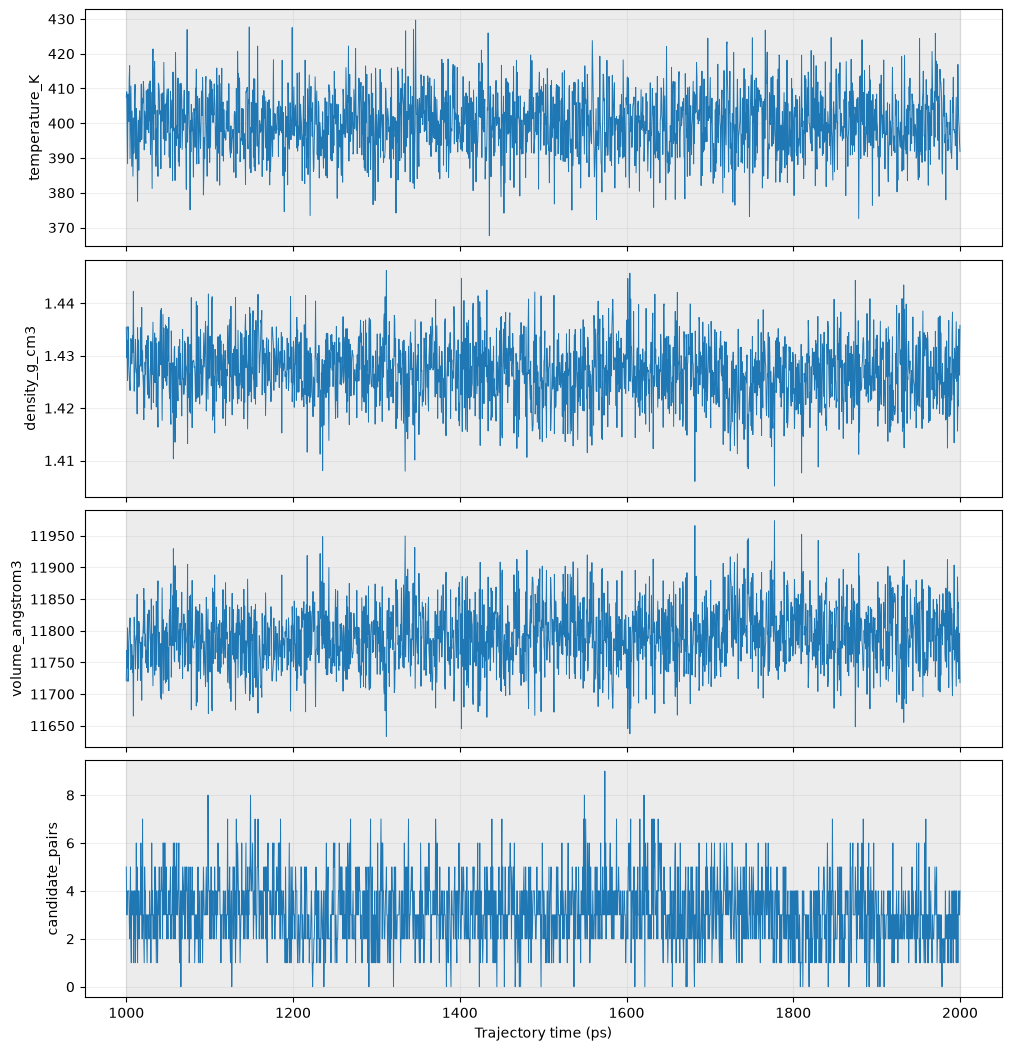

In [10]:
columns = [c for c in ("temperature_K", "density_g_cm3", "volume_angstrom3", "candidate_pairs") if c in frames]
fig, axes = plt.subplots(len(columns), 1, figsize=(10, 2.6*len(columns)), sharex=True, squeeze=False, layout="constrained")
for ax, column in zip(axes[:, 0], columns):
    ax.plot(frames.time_ps, frames[column], lw=.7)
    ax.axvspan(start, end, color="gray", alpha=.15)
    ax.set_ylabel(column)
    ax.grid(alpha=.2)
axes[-1, 0].set_xlabel("Trajectory time (ps)")
finish(fig, "frame_histories")

## Molecular COM MSD and optional diffusion fits

Each curve averages over every molecule of that formula and every available time origin within the selected window. The second panel shows how many time origins support each lag; overlapping origins are correlated.

TOR unwrapping is enabled for any fully periodic cell, including triclinic and sheared (`fix deform`) cells and moving box centers. It assumes displacements between saved source frames are smaller than half the box; that assumption cannot be proved from wrapped coordinates alone. Displacements are lab-frame: an imposed shear flow is not subtracted.

A fitted slope is not automatically a long-time diffusion coefficient. Inspect the curve and choose `DIFFUSION_FIT_PS` explicitly. Fits use MSD = intercept + 6 D × lag. Negative slopes are retained and flagged, rather than converted to positive values.

### Mathematics: molecular motion, MSD and correlations
For molecule $m$ of mass $M_m=\sum_{i\in m}m_i$, first reconstruct whole coordinates across periodic bonds:
$$\mathbf R_m=\frac{\sum_{i\in m}m_i\mathbf r_i}{M_m},\quad
\mathbf V_m=\frac{\sum_{i\in m}m_i\mathbf v_i}{M_m},\quad
\mathbf F_m=\sum_{i\in m}\mathbf F_i.$$
$\mathbf R_m$ is in Å, $\mathbf V_m$ in Å/ps, $\mathbf F_m$ in eV/Å. Whole-molecule COMs are temporally unwrapped by TOR, componentwise:
$$\mathbf d_j=\mathbf w_j-\mathbf w_{j-1},\quad
\Delta\mathbf r_j=\mathbf d_j-\mathbf L_j\left\lfloor\mathbf d_j/\mathbf L_j+\tfrac12\right\rfloor,\quad
\mathbf u_j=\mathbf u_{j-1}+\Delta\mathbf r_j.$$
$\mathbf w_j$ is the centered wrapped COM, $\mathbf L_j$ the destination box lengths, $\mathbf u_0=\mathbf w_0$. `analyze_run` updates this on every source frame before striding. This requires fixed-center orthorhombic periodic cells and sufficiently frequent source frames; no drift subtraction or finite-size correction is applied.

With $T$ selected samples and $M$ molecules of one species, lag $\tau_k=k\Delta t$:
$$\mathrm{MSD}(\tau_k)=\frac{\sum_{j=0}^{T-k-1}\sum_{m=1}^M|\mathbf u_{j+k,m}-\mathbf u_{j,m}|^2}{M(T-k)},\qquad N_{\rm origins}=T-k,$$
$$C_X(\tau_k)=\frac{\sum_{j=0}^{T-k-1}\sum_m\mathbf X_{j,m}\cdot\mathbf X_{j+k,m}}{M(T-k)}.$$
$X=V$ gives VACF in (Å/ps)²; $X=F$ gives force correlation in (eV/Å)². No temporal mean is subtracted. Plots use $C_X(\tau)/C_X(0)$ when $C_X(0)>0$. Overlapping origins are correlated. `MAX_LAG_PS` $\tau_{\max}$ retains $k\le\min(T-1,\lfloor\tau_{\max}/\Delta t\rfloor)$ in the directory workflows; in the historical report viewer it only crops the display.

If `DIFFUSION_FIT_PS=(a,b)` is supplied, an unweighted free-intercept fit minimizes
$$\sum_{a\le\tau_k\le b}[\mathrm{MSD}(\tau_k)-c-s\tau_k]^2,\qquad D=s/6.$$
$D$ in Å²/ps is multiplied by $10^{-4}$ for cm²/s or $10^{-8}$ for m²/s. Fit residual RMS is $\sqrt{\mathrm{mean}[(\mathrm{MSD}-c-s\tau)^2]}$ (Å²); it is **not** uncertainty in $D$. Notebook 08 adds the block checks below.


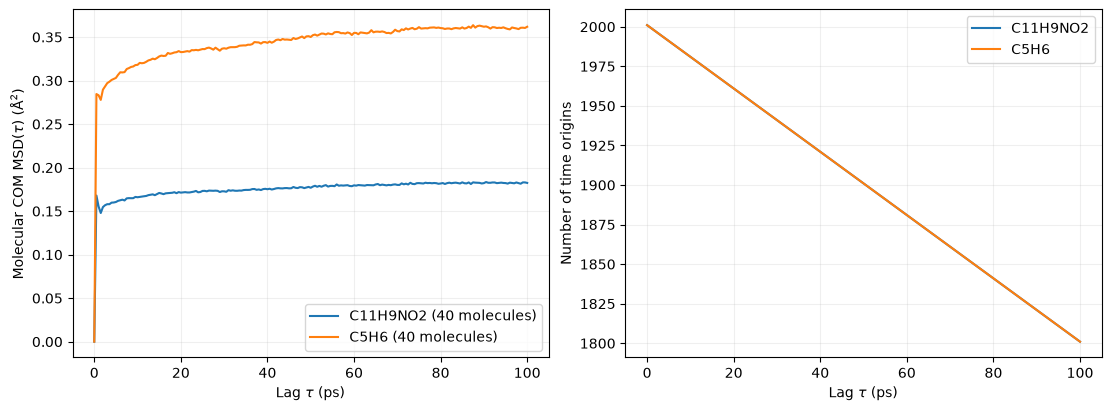

In [11]:
available = {name: data for name, data in window["species"].items() if "msd_angstrom2" in data}
if available:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    fit_rows = []
    for name, data in available.items():
        lag = data["lag_ps"]
        axes[0].plot(lag, data["msd_angstrom2"], label=f"{name} ({data['n_molecules']} molecules)")
        axes[1].plot(lag, data["n_origins"], label=name)
        if DIFFUSION_FIT_PS is not None:
            lo, hi = DIFFUSION_FIT_PS
            if not 0 <= lo < hi <= lag[-1]:
                raise ValueError("Diffusion fit must lie within the plotted lag range")
            fit = md.get_molecular_diffusion_coefficient(data, fit_start_ps=lo, fit_end_ps=hi)
            fit_rows.append(fit)
            x = np.array([lo, hi])
            axes[0].plot(x, fit["intercept_angstrom2"] + fit["slope_angstrom2_per_ps"]*x, "--")
            if fit["diffusion_cm2_per_s"] <= 0:
                print(name, ": nonpositive fitted slope is not a physical diffusion estimate.")
    axes[0].set(xlabel=r"Lag $\tau$ (ps)", ylabel=r"Molecular COM MSD($\tau$) ($\mathrm{\AA}^2$)")
    axes[1].set(xlabel=r"Lag $\tau$ (ps)", ylabel="Number of time origins")
    for ax in axes:
        ax.legend(); ax.grid(alpha=.2)
    finish(fig, "molecular_msd")
    if fit_rows:
        display(pd.DataFrame(fit_rows))
else:
    print("Molecular MSD unavailable for this cell; see notices above.")

## Displacement from a fixed reference time: MSD₀(t)

This plot follows **time since the first selected frame**, not an average over
starting times. Whole, temporally unwrapped molecular COM coordinates come from
the analysis/cache above; no dump rereading is needed.

For molecule $m$ and the first selected time $t_0$:
$$s_m(t)=\left|\mathbf R_m(t)-\mathbf R_m(t_0)\right|^2,
\qquad \mathrm{MSD}_0(t)=\frac{1}{N}\sum_{m=1}^N s_m(t).$$

The left panel shows each species' mean. On the right, thin lines show **every
molecule** of that species and the thick black line shows their mean. All values
are in Å². Reference frame/time are printed below; `reference_molecule_ids`
maps each column in `squared_displacement_angstrom2` to persistent atom IDs.

This describes net displacement accumulated **relative to t₀**, but is not a
cumulative sum of stepwise displacements or squared steps. It can decrease when
molecules return. No drift or streaming-flow subtraction is performed. The
TOR supports any fully periodic cell (including sheared); non-periodic cells are skipped.
This plot alone does not establish diffusion or equilibration.

`REFERENCE_PLOT_POINTS=2000` limits only the plotted time samples, including both
endpoints. Calculations retain every selected frame and every molecule in
`reference_msd`. Short fluctuations can be missed by this display subsampling;
set it to `None` to draw every sample. Per-molecule results require $8TN$ bytes
for $T$ selected frames and $N$ molecules, excluding input coordinates.

Here the selection follows `STARTFRAME`/`ENDFRAME`; defaults use the entire trajectory.


Reference: source frame 0, t0=1000 ps


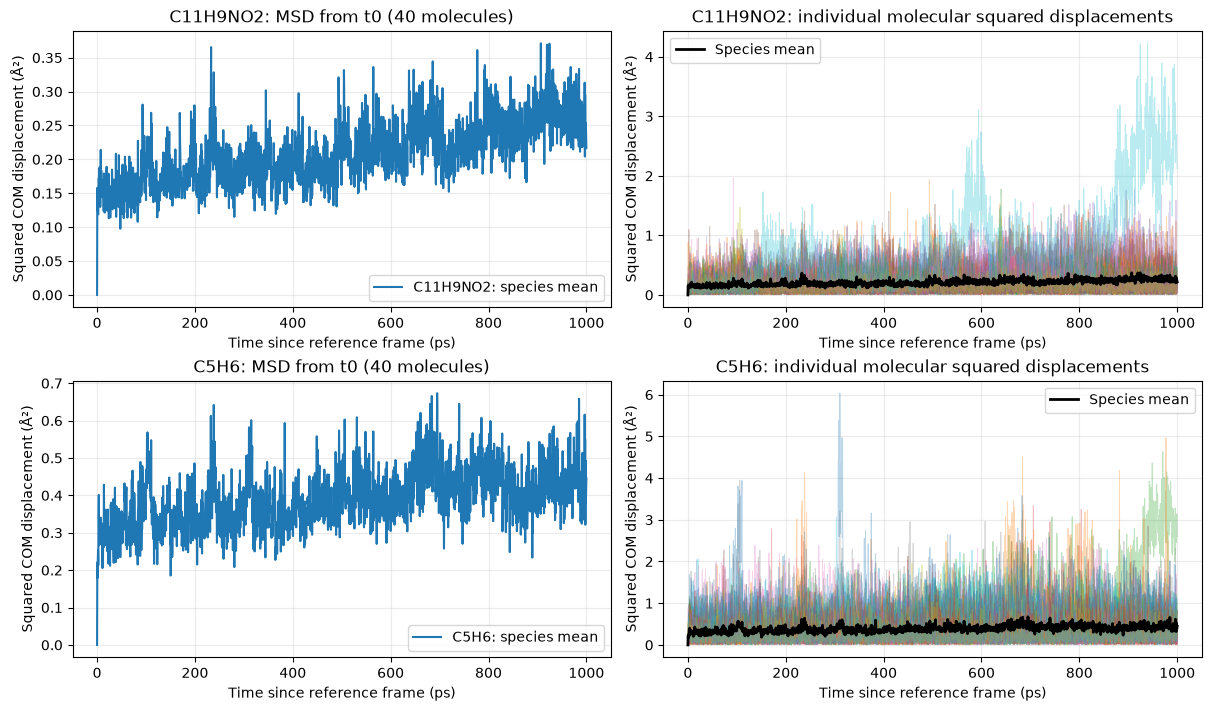

In [12]:
import importlib
from MartiniFuncs.statistics import md as reference_statistics

# An open kernel may still hold the module from before this function was added.
if not hasattr(reference_statistics, "get_molecular_reference_msd"):
    reference_statistics = importlib.reload(reference_statistics)
if not hasattr(reference_statistics, "get_molecular_reference_msd"):
    raise ImportError(
        f"Update MartiniFuncs at {reference_statistics.__file__}; "
        "this installed module does not contain get_molecular_reference_msd."
    )
get_molecular_reference_msd = reference_statistics.get_molecular_reference_msd
from MartiniFuncs.trajectory.analysis import select_frame_window

REFERENCE_PLOT_POINTS = 2000  # Display only; None plots every time sample.
reference_msd, reference_molecule_ids = {}, {}
if result.get("com_angstrom") is None:
    print("Reference MSD unavailable: the cached unwrapping/cell convention is unsupported.")
else:
    reference_mask = select_frame_window(result, startframe=STARTFRAME, endframe=ENDFRAME)
    reference_rows = [r for r, keep in zip(result["frames"], reference_mask) if keep]
    reference_times = np.array([r["time_ps"] for r in reference_rows])
    if len(reference_times) < 2:
        print("Reference MSD needs at least two selected frames.")
    else:
        reference_species = np.asarray(result["species"])
        labels = sorted(set(reference_species))
        print(f"Reference: source frame {reference_rows[0]['frame']}, t0={reference_times[0]:g} ps")
        reference_fig, reference_axes = plt.subplots(len(labels), 2, squeeze=False,
                                                      figsize=(12, 3.5*len(labels)), layout="constrained")
        sample_count = len(reference_times) if REFERENCE_PLOT_POINTS is None else min(len(reference_times), REFERENCE_PLOT_POINTS)
        plot_indices = np.unique(np.linspace(0, len(reference_times)-1, sample_count, dtype=int))
        for row, name in enumerate(labels):
            molecule_columns = np.flatnonzero(reference_species == name)
            values = result["com_angstrom"][np.ix_(np.flatnonzero(reference_mask), molecule_columns)]
            measured = get_molecular_reference_msd(values, reference_times, unwrapped=True, selection=str(name))
            reference_msd[name] = measured
            reference_molecule_ids[name] = [result["molecule_atom_ids"][i] for i in molecule_columns]
            x = measured["elapsed_time_ps"][plot_indices]
            reference_axes[row, 0].plot(x, measured["msd_angstrom2"][plot_indices], label=f"{name}: species mean")
            reference_axes[row, 1].plot(x, measured["squared_displacement_angstrom2"][plot_indices], alpha=.3, linewidth=.7)
            reference_axes[row, 1].plot(x, measured["msd_angstrom2"][plot_indices], color="black", linewidth=2, label="Species mean")
            reference_axes[row, 0].set_title(f"{name}: MSD from t0 ({len(molecule_columns)} molecules)")
            reference_axes[row, 1].set_title(f"{name}: individual molecular squared displacements")
            for ax in reference_axes[row]:
                ax.set_xlabel("Time since reference frame (ps)")
                ax.set_ylabel("Squared COM displacement (Å²)")
                ax.grid(alpha=.25)
                ax.legend()
        plt.show()


## Molecular velocity and net-force correlations

The velocity is each molecule's mass-weighted COM velocity; force is the sum of its atomic forces. Curves are dot-product averages over molecules and time origins, with no mean subtraction. The figures normalize by lag zero where nonzero. Net MD force is not an environment-only external force.

The available time resolution is the retained frame interval. A rapidly decaying velocity correlation may be unresolved even if the trajectory is long.

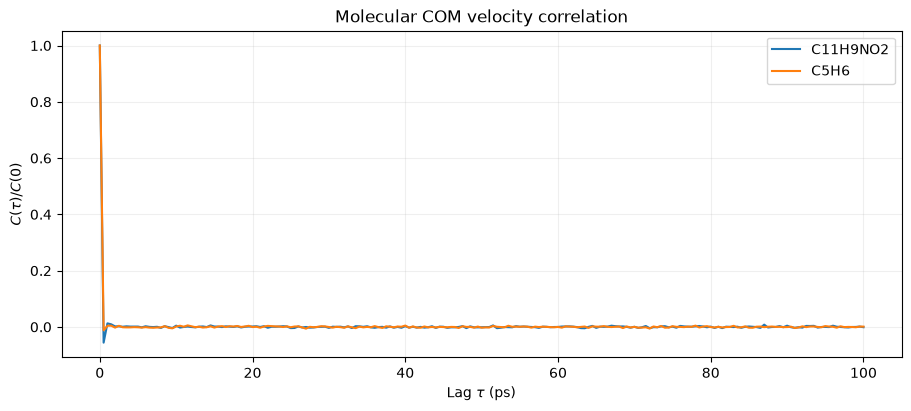

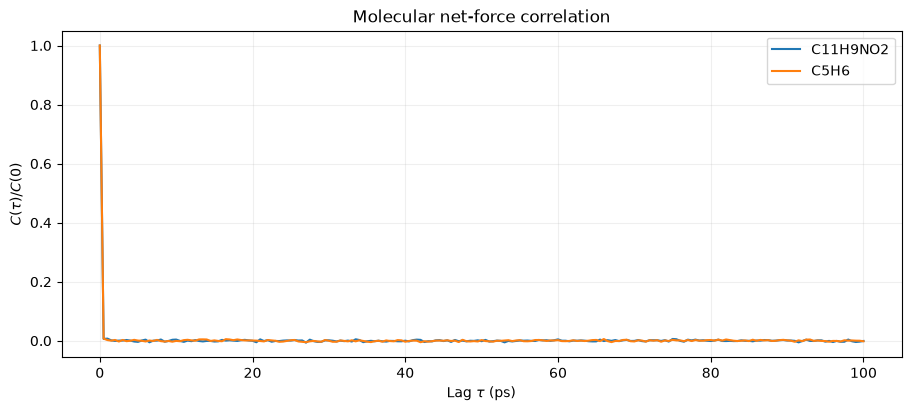

: 

In [ ]:
for key, title in (("vacf", "Molecular COM velocity correlation"), ("force_acf", "Molecular net-force correlation")):
    available = {name: data for name, data in window["species"].items() if key in data}
    if not available:
        print(title, ": required dump columns are absent.")
        continue
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    for name, data in available.items():
        correlation = data[key]
        if correlation[0] <= 0:
            print(name, ": zero signal; normalized correlation omitted.")
            continue
        ax.plot(data["lag_ps"], correlation/correlation[0], label=name)
    ax.set(title=title, xlabel=r"Lag $\tau$ (ps)", ylabel=r"$C(\tau)/C(0)$")
    ax.grid(alpha=.2); ax.legend()
    finish(fig, key)

## Optional candidate-pair persistence

Enable `COMPUTE_PAIRS` and rerun analysis to obtain counts and lifetimes for the existing CPD/dienophile screen. This can be much slower than the other metrics. Pair identities use persistent atom IDs.

Lifetime records describe continuous detections at the retained sampling interval. One-frame detections have zero observed span, not known zero physical lifetime. Records touching either analysis-window boundary are censored; their full lifetime is unknown. Striding can miss interruptions and merge apparently continuous detections. These are candidate encounters, not reactions.

### Mathematics: pair counts and observed lifetimes
A pair identity consists of two molecular atom-ID sets. The count at sample $j$ is $n_j=|P_j|$, where $P_j$ is that frame's accepted pair set. `COMPUTE_PAIRS` controls whether these sets are calculated; `PAIR_BACKEND` changes topology reuse, while `PAIR_WORKERS` and `PAIR_BATCH_SIZE` change task scheduling, not the equations (at most $2\times$ workers batches outstanding).

Consecutive detections of one identity define an encounter. These notebooks use the default zero allowed gap. Its observed span is
$$t_{\rm last\ detected}-t_{\rm first\ detected}.$$
A single-frame span is zero and its true duration is unresolved. Left/right censoring means the encounter touches the selected window boundary; completed-only histograms exclude these records. Histogram bin counts sum indicator functions for the displayed span intervals; a log y-axis changes display only. Histograms are not censoring-corrected lifetime estimates. Fixed-topology pair screening does not establish that no reaction occurred; notebook 08 has a separate size screen.


In [ ]:
if result["pairs_by_frame"] is not None:
    chosen = select_pairs(result, PAIR_CRITERIA)[0]   # every collected pair when PAIR_CRITERIA is None
    selected_pairs = [p for p, keep in zip(chosen, window["frame_mask"]) if keep]
    selected_times = frames.time_ps.to_numpy()[window["frame_mask"]]
    lifetimes = lifetimes.get_pair_lifetime(selected_pairs, selected_times)
    lifetime_table = pd.DataFrame([asdict(event) for event in lifetimes])
    display(lifetime_table.head(20))
    if len(lifetime_table):
        complete = lifetime_table[~lifetime_table.left_censored & ~lifetime_table.right_censored]
        fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
        ax.hist(complete.observed_span_ps, bins=25)
        ax.set(xlabel="Observed continuous pair span (ps)", ylabel="Uncensored detections")
        finish(fig, "pair_lifetimes")
        print("Boundary-censored records:", len(lifetime_table)-len(complete))
else:
    print("Pair analysis disabled. Enable COMPUTE_PAIRS to include it.")